# SGD NEER: multi-day signals and z-score entries

**One-day return reversal:** 2024–2025 net Sharpe **0.729 at 1.5z**, **0.544 at 2z**. The one-day equilibrium rule at 1.5z reaches **1.286**, but is much weaker in earlier development data. All results are **after spreads, with forward-point adjustments excluded** as requested.

48 declared rules, daily 16:00 New York decisions, one-minute execution, overnight/weekend holding. No candidate passed the predeclared validation-activity floor. The final period was already inspected in earlier research. [Full report and methods](sgd_neer_multiday_report.md).

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

research = next(p/s for p in [Path.cwd(), *Path.cwd().parents]
                for s in ['', 'src/systematic_trading/research/sgd_neer_codex']
                if (p/s/'sgd_neer_results/multiday/comparison_evaluation.csv').exists())
results = research/'sgd_neer_results/multiday'
evaluation = pd.read_csv(results/'comparison_evaluation.csv')
protocol = json.loads((results/'protocol.json').read_text())
params = pd.DataFrame(protocol['policies']).set_index('name')
base = evaluation.query('fill_delay_minutes == 0')
final = base.query("period == 'evaluation'").set_index('policy').join(params)
plt.rcParams.update({'figure.dpi':120, 'axes.spines.top':False, 'axes.spines.right':False, 'font.size':10})
print(protocol['financing'])


NO forward-point adjustment, explicitly requested by user.


## Longer horizons and stronger entries

Each cell shows 2024–2025 net Sharpe and completed trade count. H means past-return horizon for `return`, EWMA half-life for `equilibrium`, and both past/forward return horizon for `forecast`. Entry is |z|≥threshold plus a spread hurdle. Z-scores use past daily signal dispersion; they do not assume that minute-return variance scales linearly with time.

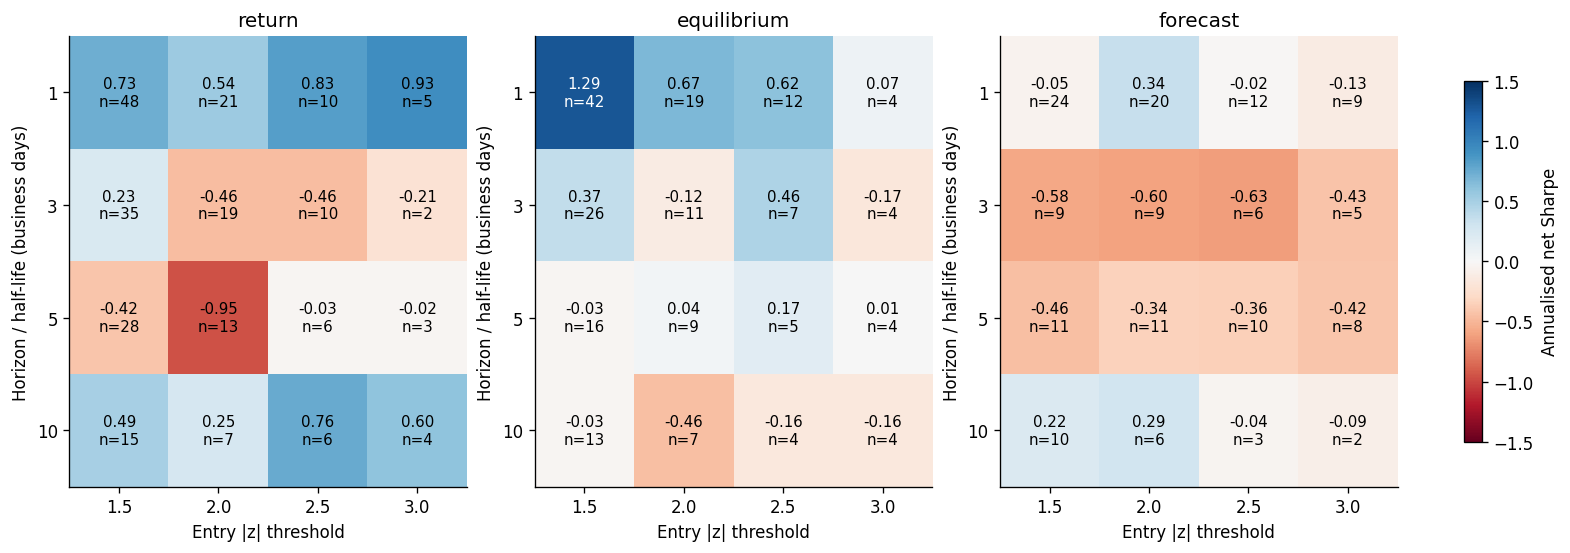

,entry_z,sharpe,completed_trades,active_days
policy,,,,
return_1d_z1.5,1.5,0.729,48,110
return_1d_z2,2.0,0.544,21,49
return_1d_z2.5,2.5,0.826,10,23
return_1d_z3,3.0,0.931,5,11


In [2]:
fig, axes = plt.subplots(1,3,figsize=(13,4.5),layout='constrained')
for ax, kind in zip(axes, ['return','equilibrium','forecast']):
    part = final.query('kind == @kind')
    scores = part.pivot(index='horizon_days',columns='entry_z',values='sharpe')
    counts = part.pivot(index='horizon_days',columns='entry_z',values='completed_trades')
    im = ax.imshow(scores, cmap='RdBu', vmin=-1.5, vmax=1.5, aspect='auto')
    for i in range(len(scores)):
        for j in range(len(scores.columns)):
            ax.text(j,i,f'{scores.iloc[i,j]:.2f}\nn={counts.iloc[i,j]}',ha='center',va='center',fontsize=9,
                    color='white' if abs(scores.iloc[i,j])>1.0 else 'black')
    ax.set_xticks(range(4),scores.columns)
    ax.set_yticks(range(4),scores.index)
    ax.set(title=kind, xlabel='Entry |z| threshold', ylabel='Horizon / half-life (business days)')
fig.colorbar(im,ax=axes,label='Annualised net Sharpe',shrink=.8)
fig.savefig(results/'horizon_threshold_grid.png',dpi=160)
plt.show()
display(final.query("kind == 'return' and horizon_days == 1")[['entry_z','sharpe','completed_trades','active_days']].round(3))


## Performance by period

The complete grid was fixed before scoring the follow-up period. These displayed one-day examples illustrate stability and trade-count tradeoffs; they are not a newly validated shortlist.

period,development,recent_development,validation,2024,2025,evaluation,all_2017_2025
policy,,,,,,,
return_1d_z1.5,0.901,0.929,0.392,1.263,0.252,0.729,0.811
return_1d_z2,0.930,1.390,0.316,0.966,0.215,0.544,0.778
return_1d_z2.5,0.396,1.031,1.273,0.799,0.858,0.826,0.498
return_1d_z3,0.123,0.277,1.273,1.415,0.491,0.931,0.339
equilibrium_1d_z1.5,0.058,0.244,0.794,1.940,0.658,1.286,0.380
equilibrium_1d_z2,0.011,0.026,1.695,1.212,0.280,0.674,0.208
forecast_1d_z2,0.804,1.031,1.273,1.257,-0.897,0.344,0.664


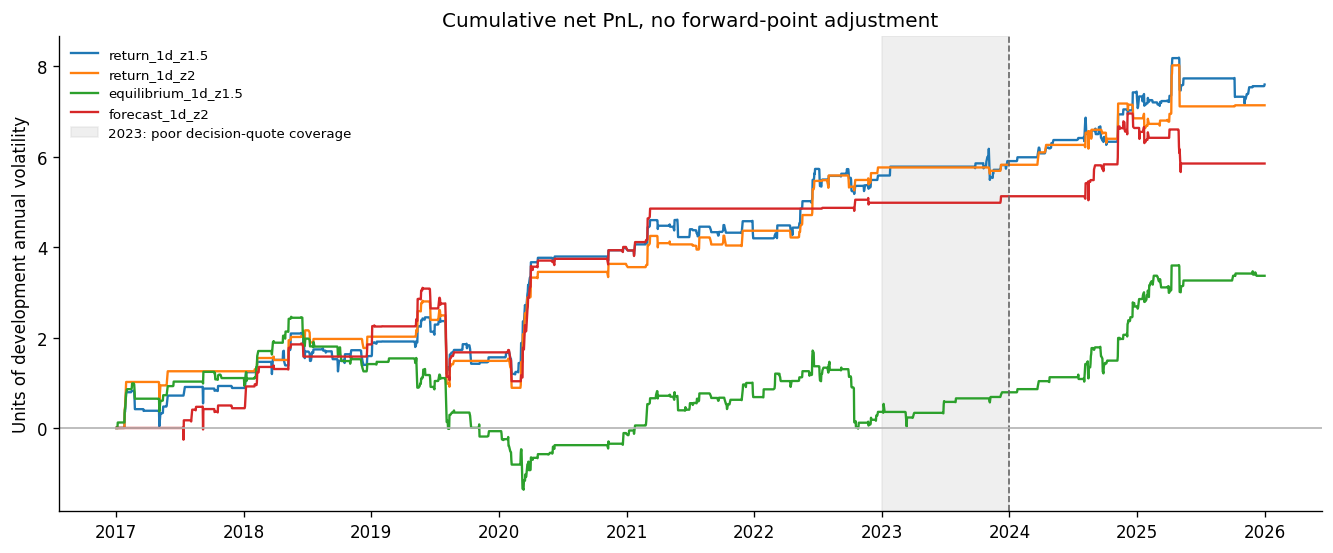

In [3]:
names = ['return_1d_z1.5','return_1d_z2','return_1d_z2.5','return_1d_z3',
         'equilibrium_1d_z1.5','equilibrium_1d_z2','forecast_1d_z2']
scores = base.pivot(index='policy',columns='period',values='sharpe')
display(scores.loc[names,['development','recent_development','validation','2024','2025','evaluation','all_2017_2025']].round(3))
fig, ax = plt.subplots(figsize=(11,4.5),layout='constrained')
for name in ['return_1d_z1.5','return_1d_z2','equilibrium_1d_z1.5','forecast_1d_z2']:
    d = pd.read_csv(results/f'daily_{name}_fill0.csv.gz',index_col=0,parse_dates=True).net
    scale = d.loc['2017':'2022'].std()*np.sqrt(252)
    ax.plot(d.loc['2017':].cumsum()/scale,label=name,lw=1.4)
ax.axvspan(pd.Timestamp('2023-01-01'),pd.Timestamp('2024-01-01'),color='0.8',alpha=.3,label='2023: poor decision-quote coverage')
ax.axvline(pd.Timestamp('2024-01-01'),color='0.4',ls='--',lw=1)
ax.axhline(0,color='0.7',lw=1)
ax.set(title='Cumulative net PnL, no forward-point adjustment',ylabel='Units of development annual volatility')
ax.legend(frameon=False,fontsize=8)
fig.savefig(results/'multiday_cumulative_pnl.png',dpi=160)
plt.show()


## Execution and spread sensitivity

Positions survive overnight and weekends. A time-limit exit is requested even when the scheduled decision quote is missing, then filled at the next available common minute quote. Held-position gap returns remain in PnL.

In [4]:
display(evaluation[(evaluation.period=='evaluation') & evaluation.policy.isin(names)].pivot(index='policy',columns='fill_delay_minutes',values='sharpe').round(3))
stress = pd.read_csv(results/'stress_evaluation.csv')
display(stress[stress.policy.isin(['return_1d_z1.5','return_1d_z2','equilibrium_1d_z1.5','equilibrium_1d_z2'])].pivot(index=['policy','scenario'],columns='fill_delay_minutes',values='sharpe').round(3))


fill_delay_minutes,0,1
policy,,
equilibrium_1d_z1.5,1.286,1.289
equilibrium_1d_z2,0.674,0.650
forecast_1d_z2,0.344,0.306
return_1d_z1.5,0.729,0.687
return_1d_z2,0.544,0.541
return_1d_z2.5,0.826,0.805
return_1d_z3,0.931,0.936


fill_delay_minutes                           0      1      15
policy              scenario                                 
equilibrium_1d_z1.5 base                  1.286  1.289  1.138
                    extra_0.25bp_per_leg  1.117  1.121    NaN
                    spread_x1.5           1.086  1.087    NaN
                    spread_x2             0.882  0.880    NaN
equilibrium_1d_z2   base                  0.674  0.650  0.511
                    extra_0.25bp_per_leg  0.588  0.563    NaN
                    spread_x1.5           0.541  0.516    NaN
                    spread_x2             0.404  0.380    NaN
return_1d_z1.5      base                  0.729  0.687  0.496
                    extra_0.25bp_per_leg  0.517  0.476    NaN
                    spread_x1.5           0.460  0.402    NaN
                    spread_x2             0.190  0.118    NaN
return_1d_z2        base                  0.544  0.541  0.348
                    extra_0.25bp_per_leg  0.433  0.430    NaN
                    spread_x1.5           0.432  0.425    NaN
                    spread_x2             0.317  0.308    NaN

## Validation coverage and uncertainty

Only 148 of 260 scheduled 16:00 quotes are available in 2023. None of the 48 candidates had both ten completed validation trades and forty active validation days, so there is no formally selected winner. Sparse-trade bootstrap intervals are conditional on nonzero-volatility resamples; discarded draw counts are reported.

In [5]:
display(pd.read_csv(results/'decision_quote_coverage.csv').round(3))
board = pd.read_csv(results/'leaderboard.csv')
display(board.head(16).round(3))
display(pd.read_csv(results/'bootstrap.csv').query('fill_delay_minutes == 0').set_index('policy').loc[names].round(3))


,Unnamed: 0,count,sum,mean
0,2016,260,259,0.996
1,2017,260,258,0.992
2,2018,261,258,0.989
3,2019,261,258,0.989
4,2020,262,259,0.989
5,2021,261,259,0.992
6,2022,260,260,1.000
7,2023,260,148,0.569
8,2024,262,253,0.966
9,2025,261,259,0.992


,policy,development,recent_development,validation,validation_completed_trades,validation_active_days,score,eligible
0,forecast_1d_z2,0.804,1.031,1.273,1,2,0.804,False
1,forecast_1d_z1.5,0.717,1.105,1.273,1,2,0.717,False
2,forecast_3d_z2.5,0.563,1.234,0.671,1,4,0.563,False
3,return_3d_z1.5,0.554,1.514,0.781,7,27,0.554,False
4,forecast_3d_z1.5,0.500,0.746,0.942,5,15,0.500,False
5,forecast_5d_z2,0.510,0.930,0.436,1,6,0.436,False
6,forecast_5d_z2.5,0.430,0.856,0.436,1,6,0.430,False
7,return_10d_z2,0.427,1.623,0.507,2,18,0.427,False
8,return_3d_z2,0.416,1.955,0.671,1,4,0.416,False
9,forecast_3d_z2,0.412,0.874,1.220,3,8,0.412,False


,fill_delay_minutes,low,median,high,draws,nonzero_vol_draws,zero_vol_draws
policy,,,,,,,
return_1d_z1.5,0,-0.366,0.723,1.829,2000,2000,0
return_1d_z2,0,-0.832,0.591,1.771,2000,2000,0
return_1d_z2.5,0,-0.602,0.831,1.713,2000,2000,0
return_1d_z3,0,-0.222,0.972,1.720,2000,1980,20
equilibrium_1d_z1.5,0,0.091,1.302,2.388,2000,2000,0
equilibrium_1d_z2,0,-0.485,0.693,1.708,2000,2000,0
forecast_1d_z2,0,-0.851,0.373,1.425,2000,2000,0


## Does return reversal survive at day-scale horizons?

Descriptive regressions use actual business-date endpoints and HAC errors for overlapping horizons. Negative coefficients support reversal; they do not by themselves establish profitability.

In [6]:
display(pd.read_csv(results/'return_regression.csv').round(4))


,period,horizon_days,beta,hac_t,r_squared,n
0,development,1,-0.1841,-5.1541,0.0338,1525
1,validation,1,-0.0577,-0.6272,0.0033,139
2,evaluation,1,-0.1106,-1.2059,0.0123,497
3,development,3,-0.0400,-0.9862,0.0016,1523
4,validation,3,0.0066,0.0685,0.0000,134
5,evaluation,3,0.0779,0.9072,0.0060,494
6,development,5,-0.0265,-0.4768,0.0007,1529
7,validation,5,-0.0113,-0.0988,0.0002,129
8,evaluation,5,0.0153,0.1793,0.0002,494
9,development,10,-0.0159,-0.2455,0.0003,1517


## Reproduce or modify a rule

```sh
poetry run python src/systematic_trading/research/sgd_neer_codex/run_sgd_neer_multiday.py
poetry run pytest -q tests/test_sgd_neer_multiday.py tests/test_sgd_neer_backtest.py
```

For a custom threshold, after adding `src/systematic_trading` to the Python path:

```python
from research.sgd_neer_codex.sgd_neer_multiday import (
    DailyPolicy, daily_marks, daily_features, daily_signal, MinuteAccountant,
)
data = pd.read_pickle('tmp/sgd_neer_m1_research/data.pkl')
marks = daily_marks(data)
features, _ = daily_features(marks, 'return', 1)
policy = DailyPolicy('custom', kind='return', horizon_days=1,
                     entry_z=2., max_hold_days=2)
signal = daily_signal(marks, features, policy)
pnl, trades = MinuteAccountant(data).run(signal, delay=1)
```

No forward-point adjustment is applied. The 2024–2025 dates were examined before this experiment and are not an untouched holdout. Minute cache quote-age limitations and transaction-cost assumptions remain applicable.